# Plot scan

In [7]:
import warnings
warnings.filterwarnings("ignore", message="numpy.dtype size changed")
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import sys
sys.path.append('../')
from auxPlots import readContours,label_line
import seaborn as sns
pd.option_context('display.max_columns', -1)

pd.options.mode.chained_assignment = None #Disable copy warnings
# plt.style.use('fivethirtyeight') #Set style
# mpl.rcParams.update({'figure.figsize' : (15,10)})  #Set general plotting options
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica"]})

plt.rcParams.update({"savefig.dpi" : 300}) #Figure resolution


#Define plotting style:
sns.set() #Set style
sns.set_style('ticks',{'font.family':'Times New Roman', 'font.serif':'Times New Roman'})
sns.set_context('paper', font_scale=1.8)
cm = plt.colormaps['RdYlBu']

#### Get contours from different sources

In [8]:

    
# mtt (CMS-TOP-20-001)
cmsMTTdict = readContours('./CMS_mtt_oneLoop_contours.csv')
print('cmsMTT=',cmsMTTdict.keys())

# mtt (CMS-TOP-20-001)
cmsMTTdict_scalar = readContours('./CMS_mtt_oneLoop_scalar_contours.csv')
print('cmsMTT=',cmsMTTdict.keys())

cmsMTTdictEFT = readContours('./CMS_mtt_eft_contours.csv')
print('cmsMTTEFT=',cmsMTTdictEFT.keys())

# Direct Searches
directDict = readContours('./SModelS_contours_VLF.csv')
print('Direct Searches=',directDict.keys())

# Direct Searches
directDict_scalar = readContours('./SModelS_contours_scalar.csv')
print('Direct Searches=',directDict_scalar.keys())


# # Direct searches (SModelS  + MonoJet)
# directDict = {}
# cVals = set(smodelsDict.keys()).intersection(set(monoJetDict.keys()))
# for c in cVals:
#     smodelsCurve = np.array([list(x) for x in smodelsDict[c]])
#     monoJetCurve = np.array([list(x) for x in monoJetDict[c]])
#     # interpolate in y vs x to get most constraining curve
#     f_smodels = interp1d(smodelsCurve[:,1],smodelsCurve[:,0],
#                          fill_value=-1,bounds_error=False)
#     f_mono = interp1d(monoJetCurve[:,1],monoJetCurve[:,0],
#                       fill_value=-1,bounds_error=False)
#     # Get all 
#     ypts = np.array(sorted(list(set(smodelsCurve[:,1].tolist()+monoJetCurve[:,1].tolist()))))
#     combCurve = np.array([(max(f_smodels(y),f_mono(y)),y) for y in ypts],
#                          dtype=smodelsDict[c].dtype)
#     directDict[c] = combCurve
    
# print('direct=',directDict.keys())


cmsMTT= dict_keys([5.0, 10.0, 12.57, 15.0, 20.0])
cmsMTT= dict_keys([5.0, 10.0, 12.57, 15.0, 20.0])
cmsMTTEFT= dict_keys([5.0, 10.0, 12.57, 15.0, 20.0])
Direct Searches= dict_keys([0.67, 1.0])
Direct Searches= dict_keys([(0.67,), (1.0,)])


## Version 1

In [9]:
# Select contour values:
colors = sns.color_palette('deep')
plots = {
        # 'Mono Jet' : {'contour' : 1.0, 'dataDict' : monoJetDict, 
                    #    'fill' : True, 'linestyle' : 'solid', 'color' : colors[0]},
        #  r'Stop Searches ($k=1.5$)' : {'contour' : 0.67, 'dataDict' : directDict, 
                            # 'fill' : True, 'linestyle' : 'solid', 'color' : colors[1]},
         #r'Direct Searches' : {'contour' : 0.66, 'dataDict' : directDict, 
                            #'fill' : True, 'linestyle' : 'solid', 'color' : colors[1]},                            
          r'$m(t\bar{t})$, $y_{DM} = 5$ (1-loop)' : {'contour' : 5.0, 'dataDict' : cmsMTTdict, 
                                                     'fill' : False, 'linestyle' : 'solid', 'color' : colors[6]},
         #r'$m(t\bar{t})$, $y_{DM} = 5$ (EFT)' : {'contour' : 5.0, 'dataDict' : cmsMTTdictEFT, 
                                                     #'fill' : False, 'linestyle' : 'dashed', 'color' : colors[6]},
          r'$m(t\bar{t})$, $y_{DM} = 10$ (1-loop)' : {'contour' : 10.0, 'dataDict' : cmsMTTdict, 
                                                     'fill' : False, 'linestyle' : 'solid', 'color' : colors[6]},
         r'$m(t\bar{t})$, $y_{DM} = 10$ (EFT)' : {'contour' : 10.0, 'dataDict' : cmsMTTdictEFT, 
                                                  #'fill' : False, 'linestyle' : 'dashed', 'color' : colors[6]},
          r'$m(t\bar{t})$, $y_{DM} = 12$ (EFT)' : {'contour' : 12.0, 'dataDict' : cmsMTTdictEFT, 
                                                #   'fill' : False, 'linestyle' : 'dashed', 'color' : colors[3]},
         #r'$p_T(t_h)$, $y_{DM} = 5$ (1-loop)' : {'contour' : 5.0, 'dataDict' : atlasPTdict, 
                                                     #'fill' : False, 'linestyle' : 'solid', 'color' : colors[3]},
        #r'$p_T(t_h)$, $y_{DM} = 5$ (EFT)' : {'contour' : 5.0, 'dataDict' : atlasPTdictEFT, 
                                                  #'fill' : False, 'linestyle' : 'dashed', 'color' : colors[3]},
         #r'$p_T(t_h)$, $y_{DM} = 10$ (1-loop)' : {'contour' : 10.0, 'dataDict' : atlasPTdict, 
                                                     #'fill' : False, 'linestyle' : 'solid', 'color' : colors[2]},         
        #  r'$p_T(t_h)$, $y_{DM} = 5$ (EFT)' : {'contour' : 5.0, 'dataDict' : atlasPTdictEFT, 
                                                #   'fill' : False, 'linestyle' : 'dashed', 'color' : colors[5]},
        #r'$p_T(t_h)$, $y_{DM} = 10$ (EFT)' : {'contour' : 10.0, 'dataDict' : atlasPTdictEFT, 
                                                  #'fill' : False, 'linestyle' : 'dashed', 'color' : colors[2]},

         }


_IncompleteInputError: incomplete input (2276675467.py, line 31)

### Plot Exclusions

In [10]:
plt.figure(figsize=(8,5))

for p,pInfo in plots.items():
    data = pInfo['dataDict'][pInfo['contour']]
    x = data['mPsiT_GeV']
    y = data['deltaM_GeV']    
    plt.plot(x,y,label=p,linewidth=2,color=pInfo['color'],linestyle=pInfo['linestyle'])
    if pInfo['fill']:
        plt.fill_betweenx(y,x,200,alpha=0.3,color=pInfo['color'])

plt.fill_betweenx([200.,600.],[200.,600.],color='lightgray',alpha=1.0,zorder=2)
plt.text(210.,400.,r'$m_T < m_{\chi}$',fontsize=17)


plt.legend(loc=(0.7,0.1),fontsize=14,framealpha=1.0)
plt.yscale('log')
plt.xlabel(r'$m_{T}$ (GeV)')
plt.ylabel(r'$\Delta M$ (GeV)')
plt.ylim(10.,550.)
plt.xlim(200.,3050.)
plt.tight_layout()
plt.savefig('allExclusions.png')
plt.show()

NameError: name 'plots' is not defined

<Figure size 800x500 with 0 Axes>

## Version 2

In [11]:
# Select contour values:
colors = sns.color_palette('Paired')
plots = {
         'Direct Searches VLF' : {'contour' : 0.67, 'dataDict' : directDict, 'label' : 'Direct Searches VLF', 'textLabel' : 'Direct Searches', 'textoffset' : +98,                             
                              'fill' : True, 'linestyle' : 'solid', 'color' : 'red'},   
         r'$m(t\bar{t})$, $y_{DM} = 10$ (1-loop)' : {'contour' : 10.0, 'dataDict' : cmsMTTdict, 
                                                     'label' : r'CMS - $m(\bar{t} t)$', 'textLabel' : r'$y_{DM} = 10$ (1-loop)','textoffset' : -38,
                                                     'fill' : True, 'linestyle' : 'solid', 'color' : colors[1]},
         r'$m(t\bar{t})$, $y_{DM} = 5$ (1-loop)' : {'contour' : 5.0, 'dataDict' : cmsMTTdict, 
                                                     'label' : r'CMS - $m(\bar{t} t)$', 'textLabel' : r'$y_{DM} = 5$ (1-loop)','textoffset' : -42,
                                                     'fill' : True, 'linestyle' : 'solid', 'color' : colors[3]},
         r'$m(t\bar{t})$, $y_{DM} = 4\pi$ (1-loop)' : {'contour' : 12.57, 'dataDict' : cmsMTTdict, 
                                                     'label' : r'CMS - $m(\bar{t} t)$', 'textLabel' : r'$y_{DM} = 4\pi$ (1-loop)','textoffset' : -38,
                                                     'fill' : True, 'linestyle' : 'solid', 'color' : colors[4]},
         #r'$m(t\bar{t})$, $y_{DM} = 10$ (EFT)' : {'contour' : 10.0, 'dataDict' : cmsMTTdictEFT, 
          #                                       'label' : None,'textLabel' : r'$y_{DM} = 10$ (EFT)','textoffset' : -38,
           #                                       'fill' : False, 'linestyle' : 'dashed', 'color' : colors[5]},
         #'$m(t\bar{t})$, $y_{DM} = 5$ (EFT)' : {'contour' : 5.0, 'dataDict' : cmsMTTdictEFT, 
           #                                      'label' : None,'textLabel' : r'$y_{DM} = 5$ (EFT)','textoffset' : -38,
            #                                      'fill' : False, 'linestyle' : 'dashed', 'color' : colors[7]},
        #r'$m(t\bar{t})$, $y_{DM} = 10$ (1-loop)' : {'contour' : 10.0, 'dataDict' : cmsMTTdict_scalar, 
         #                                            'label' : r'CMS - $m(\bar{t} t)$', 'textLabel' : r'$y_{DM} = 10$ (1-loop Scalar)','textoffset' : -38,
          #                                           'fill' : True, 'linestyle' : 'solid', 'color' : colors[0]},
         #r'$m(t\bar{t})$, $y_{DM} = 5$ (1-loop)' : {'contour' : 5.0, 'dataDict' : cmsMTTdict_scalar, 
          #                                           'label' : r'CMS - $m(\bar{t} t)$', 'textLabel' : r'$y_{DM} = 5$ (1-loop Scalar)','textoffset' : -42,
           #                                          'fill' : True, 'linestyle' : 'solid', 'color' : colors[8]},
         #r'$m(t\bar{t})$, $y_{DM} = 4\pi$ (1-loop)' : {'contour' : 12.57, 'dataDict' : cmsMTTdict_scalar, 
          #                                           'label' : r'CMS - $m(\bar{t} t)$', 'textLabel' : r'$y_{DM} = 4\pi$ (1-loop Scalar)','textoffset' : -38,
           #                                          'fill' : True, 'linestyle' : 'solid', 'color' : colors[5]},
         #r'$p_T(t_h)$, $y_{DM} = 5$ (1-loop)' : {'contour' : 5.0, 'dataDict' : atlasPTdict, 
             #                                       'label' : r'ATLAS - $p_T(t)$', 'textLabel' : r'$y_{DM} = 5$ (1-loop)','textoffset' : -10,
              #                                       'fill' : False, 'linestyle' : 'solid', 'color' : colors[5]},
        #r'$p_T(t_h)$, $y_{DM} = 5$ (EFT)' : {'contour' : 5.0, 'dataDict' : atlasPTdictEFT, 'textoffset' : -10,
         #                                           'label' : None, 'textLabel' : r'$y_{DM} = 5$ (EFT)',
            #                                      'fill' : False, 'linestyle' : 'dashed', 'color' : colors[5]},
         #r'$p_T(t_h)$, $y_{DM} = 10$ (1-loop)' : {'contour' : 10.0, 'dataDict' : atlasPTdict, 
          #                                           'label' : None, 'textLabel' : r'$y_{DM} = 10$ (1-loop)','textoffset' : 20,
           #                                          'fill' : False, 'linestyle' : 'solid', 'color' : colors[5]},
        #r'$p_T(t_h)$, $y_{DM} = 10$ (EFT)' : {'contour' : 10.0, 'dataDict' : atlasPTdictEFT, 
         #                                         'label' : None, 'textLabel' : r'$y_{DM} = 10$ (EFT)','textoffset' : 20,
          #                                        'fill' : False, 'linestyle' : 'dashed', 'color' : colors[5]},

         }

In [12]:
print("cmsMTTdict keys:", cmsMTTdict_scalar.keys())

cmsMTTdict keys: dict_keys([12.57, 15.0, 20.0])


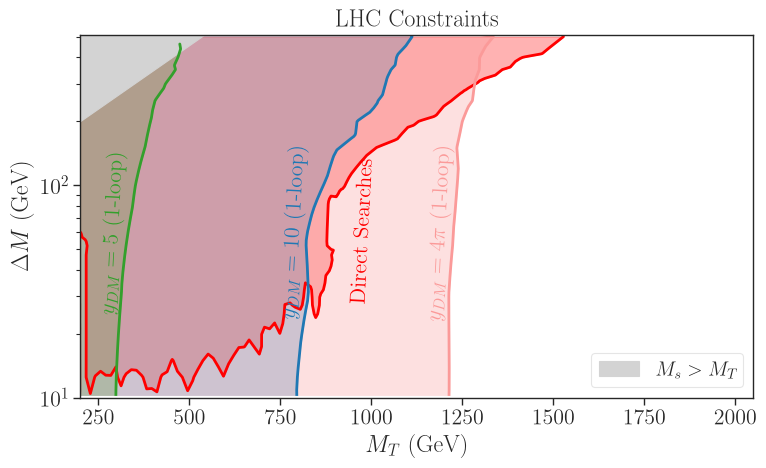

In [13]:
fig = plt.figure(figsize=(8,5))

for p,pInfo in plots.items():
    data = pInfo['dataDict'][pInfo['contour']]
    x = data['mPsiT_GeV']
    y = data['deltaM_GeV']
    # if any(x > 450.):
        # y = y[x>450.]
        # x = x[x>450.]
    label = pInfo['label']
    txtLabel = pInfo['textLabel']
    l, = plt.plot(x,y,linewidth=2,color=pInfo['color'],linestyle=pInfo['linestyle'])
    if txtLabel:
        label_line(fig,l, txtLabel, near_y=60.,
                rotation=87.,fontsize=16,
                xmin=200.,offset=(pInfo['textoffset'],0.),boxalpha=0.0)
    
    if pInfo['fill']:
        plt.fill_betweenx(y,x,200,alpha=0.3,color=pInfo['color'])
        

plt.fill_betweenx([200.,600.],[200.,600.],color='lightgray',alpha=1.0, label = r'$M_s > M_{T}$')
# plt.text(210.,400.,r'$m_T < m_{\chi}$',fontsize=17)
plt.hlines(y=10.,xmin=0.,xmax=2000.,colors='white',linewidth=3)

plt.legend(loc= 'lower right',fontsize=14.5,framealpha=0.5)
plt.yscale('log')
plt.xlabel(r'$M_{T}$ (GeV)')
plt.ylabel(r'$\Delta M$ (GeV)')
plt.xlim(200,2050)
plt.ylim(10,510)
plt.title('LHC Constraints')
plt.tight_layout()
plt.savefig('allExclusions_v2.png')
plt.show()

In [18]:
# Select contour values:
colors = sns.color_palette('Paired')
plots = {
         'Direct Searches VLF' : {'contour' : 0.67, 'dataDict' : directDict, 'label' : ' VLF', 'textLabel' : None,                              
                              'fill' : True, 'linestyle' : 'solid', 'color' : plt.cm.tab10.colors[2]}, 
          'Direct Searches Scalar' : {'contour' : (0.67,), 'dataDict' : directDict_scalar, 'label' : 'Scalar', 'textLabel' : '', 'textoffset' : -38,                             
                              'fill' : True, 'linestyle' : 'solid', 'color' : plt.cm.tab10.colors[0]}, 

         }

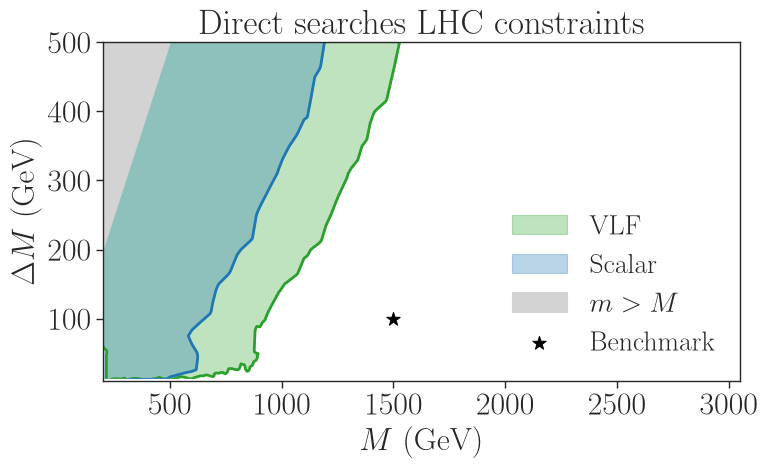

In [21]:
fig = plt.figure(figsize=(8,5))

for p,pInfo in plots.items():
    data = pInfo['dataDict'][pInfo['contour']]
    x = data['mPsiT_GeV']
       
    y = data['deltaM_GeV']
    # if any(x > 450.):
        # y = y[x>450.]
        # x = x[x>450.]
    label = pInfo['label']
    txtLabel = pInfo['textLabel']
    l, = plt.plot(x,y,linewidth=2,color=pInfo['color'],linestyle=pInfo['linestyle'])
    if txtLabel:
        label_line(fig,l, txtLabel, near_y=60.,
                rotation=87.,fontsize=16,
                xmin=200.,offset=(pInfo['textoffset'],0.),boxalpha=0.0)
    
    if pInfo['fill']:
        plt.fill_betweenx(y,x,200,alpha=0.3,color=pInfo['color'], label =pInfo['label'])
        

plt.fill_betweenx([200.,600.],[200.,600.],color='lightgray',alpha=1.0, label = r'$m > M$')
plt.scatter([1500.0], [100.0], marker = '*', s= 100, edgecolor = 'black', color = 'black', label = 'Benchmark')

# plt.text(210.,400.,r'$m_T < m_{\chi}$',fontsize=17)
plt.hlines(y=10.,xmin=0.,xmax=2000.,colors='white',linewidth=3)
#plt.scatter([1000], [100], )

plt.legend(loc= 'lower right',fontsize=20,framealpha=0)
#plt.yscale('log')
plt.xlabel(r'$M$ (GeV)', fontsize = 23)
plt.ylabel(r'$\Delta M$ (GeV)', fontsize = 23)
plt.xlim(200,3050)
plt.ylim(10,500)
plt.tick_params(axis = 'both', labelsize = 23)
plt.title('Direct searches LHC constraints', fontsize = 25)
plt.tight_layout()
plt.savefig('Direct_Exclusions.png')
plt.show()